# GIS dashboard: maps, explanations and what-if on a drawn district

Member 4, step 3 (slides 23–24). `urbanheat serve` starts a FastAPI app (`urbanheat.app.server`) with a Leaflet
map (`src/urbanheat/app/static/index.html`):

| Endpoint | Returns |
|---|---|
| `GET /api/cities` | 422 cities (test first), layer list, scenario presets |
| `GET /api/layer/{city}/{layer}` | transparent PNG + EPSG:4326 bounds + legend: observed / predicted LST, anomaly, error, true colour, NDVI, NDBI, MNDWI, built share, thermal context, IG attribution per factor, Grad-CAM |
| `POST /api/explain` | facts and factor contributions (°C) for a drawn polygon or the whole city; Grad-CAM for the polygon |
| `POST /api/scenario` | ΔLST map and statistics for lever changes inside a drawn polygon (Member 3's engine) |
| `POST /api/ask` | the assistant from `02_genai_rag`, with the facts of the selected place |

Run it:  `urbanheat serve`  then open http://127.0.0.1:8000. The model is Member 3's `m3_lite16_kd` (CPU is enough).
Below, the same API is called from Python and the returned map layers are drawn.

In [1]:
import warnings, base64, io, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from fastapi.testclient import TestClient
from urbanheat.app import assistant
from urbanheat.app.server import create_app, PRESETS
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 90
app = create_app()                     # dataset from the config, model runs/m3_lite16_kd
ws, api = app.state.ws, TestClient(app)
PID = "EMIT_243"
lay = api.get(f"/api/layer/{PID}/lst").json()
(s, w), (n, e) = lay["bounds"]
cy, cx, d = (s + n) / 2, (w + e) / 2, (n - s) * 0.12
DISTRICT = {"type": "Polygon", "coordinates": [[[cx - d, cy - d], [cx + d, cy - d], [cx + d, cy + d], [cx - d, cy + d], [cx - d, cy - d]]]}
print(ws.run, "|", len(ws.info), "cities | district of", PID, "around", round(cy, 4), round(cx, 4))

m3_lite16_kd | 422 cities | district of EMIT_243 around 10.9349 -74.8251


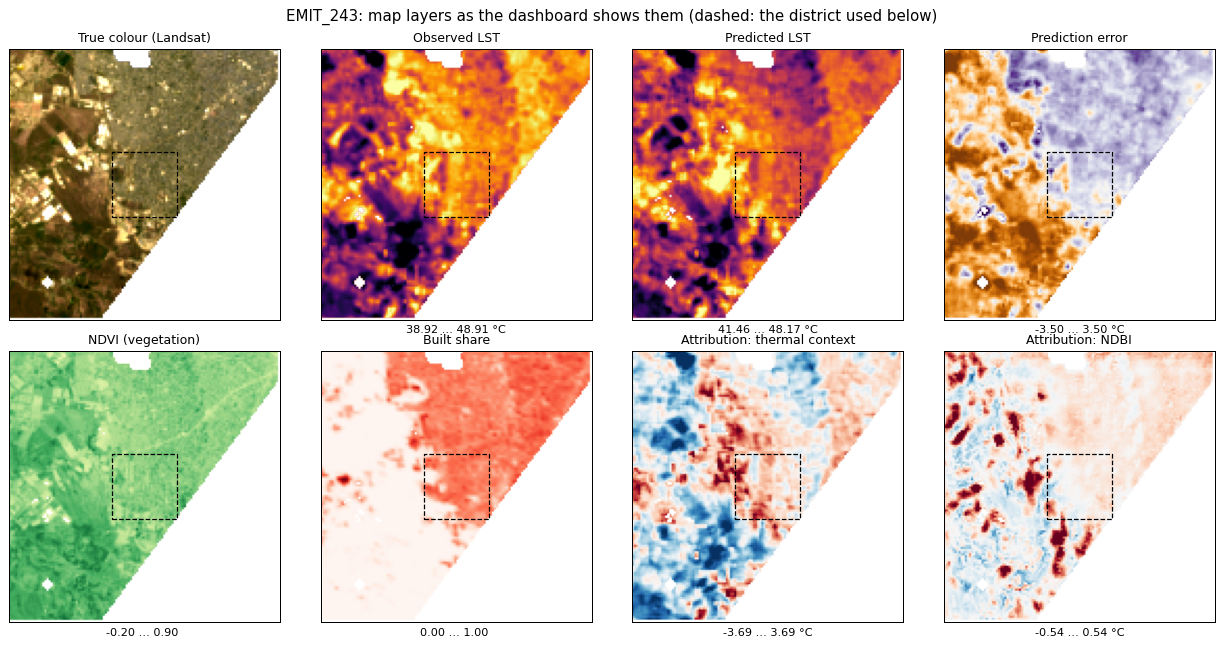

In [2]:
def img(layer):
    return np.asarray(Image.open(io.BytesIO(base64.b64decode(layer["url"].split(",", 1)[1]))))

names = ["rgb", "lst", "pred", "error", "NDVI", "built_share", "attr_thermal context", "attr_NDBI"]
fig, axs = plt.subplots(2, 4, figsize=(14, 7.2))
for ax, nm in zip(axs.flat, names):
    L = api.get(f"/api/layer/{PID}/{nm}").json()
    (s0, w0), (n0, e0) = L["bounds"]
    ax.imshow(img(L), extent=[w0, e0, s0, n0]); ax.set_title(L["label"], fontsize=10)
    if L["vmin"] is not None: ax.set_xlabel(f"{L['vmin']:.2f} … {L['vmax']:.2f} {L['unit']}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    ax.plot(*np.array(DISTRICT["coordinates"][0]).T, "k--", lw=1)
plt.suptitle(f"{PID}: map layers as the dashboard shows them (dashed: the district used below)"); plt.tight_layout(); plt.show()

## Why is the district hot?

,district
city,EMIT_243
sensor,EMIT
climate,tropical
landsat_date,2025-03-11
region,drawn polygon
pixels,1023
city_median_lst_c,45.23
predicted_anomaly_c,+0.77 °C
observed_anomaly_c,+1.11 °C
top_factors,"thermal context +0.88 °C, landsat bands -0.06 ..."


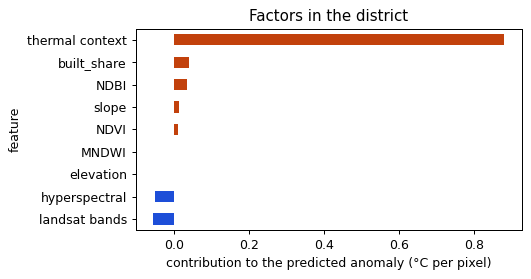

Attributions describe what the model learned from data (associations), not physical causes.


In [3]:
ex = api.post("/api/explain", json={"pid": PID, "geometry": DISTRICT}).json()
display(pd.Series(ex["facts"]).to_frame("district"))
f = pd.DataFrame(ex["factors"]).set_index("feature")["mean_c"]
f.sort_values().plot.barh(figsize=(6, 3.2), color=["#c2410c" if v > 0 else "#1d4ed8" for v in f.sort_values()])
plt.xlabel("contribution to the predicted anomaly (°C per pixel)"); plt.title("Factors in the district"); plt.tight_layout(); plt.show()
print(ex["note"])

## What if the district changes?

,changes,mean_inside_c,min_inside_c,max_inside_c,pixels_inside,mean_outside_c
scenario,,,,,,
built_to_green,"{""NDVI"": 0.34, ""NDBI"": -0.2, ""built_share"": -0.3}",-0.185,-1.235,0.200,1023,0.016
green_to_built,"{""NDVI"": -0.34, ""NDBI"": 0.2, ""built_share"": 0.3}",0.099,-1.150,0.584,1023,-0.010
greening,"{""NDVI"": 0.1, ""NDBI"": -0.06}",-0.104,-0.564,0.010,1023,0.003
densify,"{""built_share"": 0.1}",-0.068,-0.676,0.095,1023,-0.002


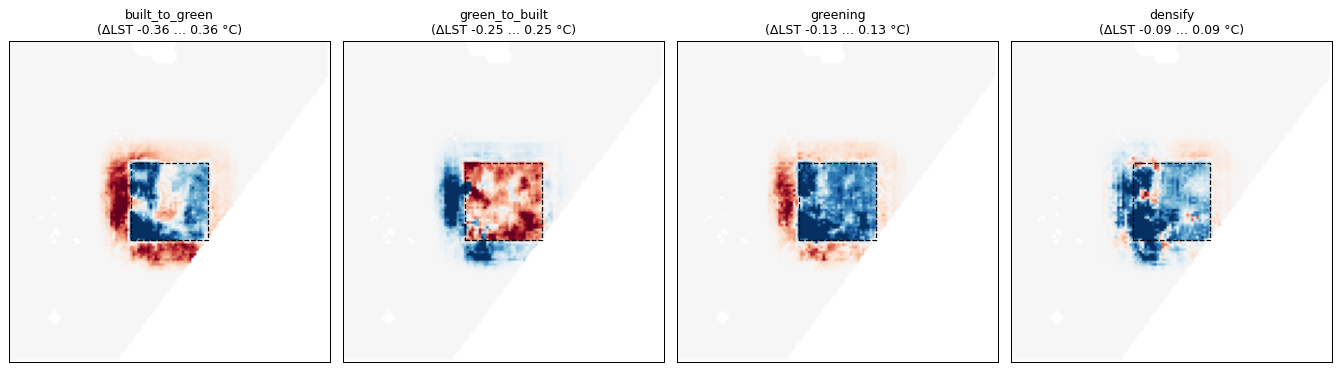

Modelled estimate of land surface temperature change; not a causal guarantee.
A region is required: draw a region: the target is an anomaly from the city median, so a whole-city change has no meaningful effect


In [4]:
rows, maps = [], {}
for name, ch in {**PRESETS, "densify": {"built_share": 0.1}}.items():
    r = api.post("/api/scenario", json={"pid": PID, "geometry": DISTRICT, "name": name, "changes": ch}).json()
    rows.append(dict(scenario=name, changes=json.dumps(ch), **{k: round(v, 3) for k, v in r["stats"].items()}))
    maps[name] = r["layer"]
display(pd.DataFrame(rows).set_index("scenario"))
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for ax, (name, L) in zip(axs, maps.items()):
    (s0, w0), (n0, e0) = L["bounds"]
    ax.imshow(img(L), extent=[w0, e0, s0, n0]); ax.plot(*np.array(DISTRICT["coordinates"][0]).T, "k--", lw=1)
    ax.set_title(f"{name}\n(ΔLST {L['vmin']:.2f} … {L['vmax']:.2f} °C)", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
print(r["note"])
print("A region is required:", api.post("/api/scenario", json={"pid": PID, "name": "greening", "changes": {"NDVI": 0.1}}).json()["detail"])

## Map export (CONTRACTS section 5)

In [5]:
from urbanheat.explain import xai
s = ws.scene(PID)
out = Path("../../runs/m3_lite16_kd/maps"); out.mkdir(parents=True, exist_ok=True)
p = xai.write_bands(out / f"{PID}_pred.tif", {"predicted_lst_c": ws.pred(PID) + ws.info[PID]["median"]}, ws.h5, PID,
                    mask=s["mask"], model=ws.run, note="Predicted land surface temperature (deg C), not air temperature.")
import rasterio
with rasterio.open(p) as r:
    print(p.name, r.crs, r.shape, r.descriptions, "| no uncertainty band: every model was trained once (one seed)")

EMIT_243_pred.tif EPSG:4326 (130, 130) ('predicted_lst_c',) | no uncertainty band: every model was trained once (one seed)


## Notes

- The page loads Leaflet 1.9.4 from unpkg and the OpenStreetMap tiles, so the browser needs internet access. The
  API itself runs offline.
- Every layer, explanation and scenario carries the caveats: surface (not air) temperature, model estimates
  rather than causes, and scenario responses about half the observed size.
- The ΔLST maps show a ring of the **opposite sign just outside the district** (up to about ±0.3 °C, mean outside
  about 0.01 °C). The model reads surface factors relative to their surroundings (`01_xai`), so a change also alters
  the contrast seen by neighbouring pixels. Read the mean inside the district, not single pixels at its edge.
- `densify` (built share alone) has no measurable effect in this model (`01_xai`, point 4); the dashboard shows the
  number as it is.
- Startup reads the dataset (about 12 s). The integrated gradients of a city are computed on first use (about 3 s
  on CPU) and then cached.